# UCS420 Cognitive Computing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Q1. You are a data analyst at an e-commerce company. Your task is to analyze sales data, clean and process it, perform statistical analysis, and generate visual insights to help the business make informed decisions.

1. Use your roll number as the random seed to generate unique data for each student.
2. Follow the questions step by step, as each part builds upon the previous one.
3. Submit the assignment as a Jupyter Notebook (.ipynb) with:
    - Well-documented code and clear comments.
    - Markdown explanations for each step.
    - Screenshots of the plots and outputs.

#### Part I: Randomized Sales Data Generation (NumPy)

1. Initialize Random Seed

The roll number is used as the seed so the same data is generated every time.

In [2]:
roll = 1024170173
np.random.seed(roll)

2. Generate Sales Data

- Create a NumPy array of random sales data for 12 months (shape = (12, 4)), where each column represents a product category: Electronics, Clothing, Home & Kitchen, Sports.
- Sales values should be between 1000 and 5000 units per month.
- The range should be randomized using the seed.

In [3]:
sales = np.random.randint(1000, 5001, size=(12, 4))
print(sales.shape)
print(sales)

(12, 4)
[[2804 3081 4223 4796]
 [2603 3468 3106 1082]
 [4135 2633 4155 2060]
 [1407 2116 1131 1913]
 [2680 4252 2349 3505]
 [3315 3915 1497 1580]
 [4452 2016 1825 3131]
 [4990 2418 2110 3162]
 [1284 4842 2084 3151]
 [3249 4913 4987 3749]
 [1343 2130 2066 2567]
 [1110 3272 4458 4469]]


3. Convert to DataFrame

- Convert the cleaned NumPy array into a Pandas DataFrame with:
    - Columns: Electronics, Clothing, Home & Kitchen, Sports
    - Index: Months from Jan to Dec

In [4]:
categories = ["Electronics", "Clothing", "Home & Kitchen", "Sports"]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df = pd.DataFrame(sales, columns=categories, index=months)
df

,Electronics,Clothing,Home & Kitchen,Sports
Jan,2804,3081,4223,4796
Feb,2603,3468,3106,1082
Mar,4135,2633,4155,2060
Apr,1407,2116,1131,1913
May,2680,4252,2349,3505
Jun,3315,3915,1497,1580
Jul,4452,2016,1825,3131
Aug,4990,2418,2110,3162
Sep,1284,4842,2084,3151
Oct,3249,4913,4987,3749


#### Part II: Data Manipulation and Analysis (Pandas)

1. Display the first 5 rows and summary statistics of the DataFrame.

In [5]:
print(df.head())
print(df.describe())

     Electronics  Clothing  Home & Kitchen  Sports
Jan         2804      3081            4223    4796
Feb         2603      3468            3106    1082
Mar         4135      2633            4155    2060
Apr         1407      2116            1131    1913
May         2680      4252            2349    3505
       Electronics     Clothing  Home & Kitchen       Sports
count    12.000000    12.000000       12.000000    12.000000
mean   2781.000000  3254.666667     2832.583333  2930.416667
std    1315.667891  1042.662443     1301.701366  1134.399678
min    1110.000000  2016.000000     1131.000000  1082.000000
25%    1391.000000  2346.000000     2005.750000  2023.250000
50%    2742.000000  3176.500000     2229.500000  3141.000000
75%    3520.000000  3999.250000     4172.000000  3566.000000
max    4990.000000  4913.000000     4987.000000  4796.000000


2. Calculate the total sales per category and total sales per month.

In [6]:
print("Total sales per category")
print(df.sum())
print("\nTotal sales per month")
print(df.sum(axis=1))

Total sales per category
Electronics       33372
Clothing          39056
Home & Kitchen    33991
Sports            35165
dtype: int64

Total sales per month
Jan    14904
Feb    10259
Mar    12983
Apr     6567
May    12786
Jun    10307
Jul    11424
Aug    12680
Sep    11361
Oct    16898
Nov     8106
Dec    13309
dtype: int64


3. Calculate the average sales growth between consecutive months for each category.

In [7]:
print("Average monthly growth (units)")
print(df.diff().mean())
print("\nAverage monthly growth (%)")
print(df.pct_change().mean() * 100)

Average monthly growth (units)
Electronics      -154.000000
Clothing           17.363636
Home & Kitchen     21.363636
Sports            -29.727273
dtype: float64

Average monthly growth (%)
Electronics       13.547471
Clothing          11.998752
Home & Kitchen    21.705985
Sports            17.678363
dtype: float64


4. Add the following columns to the DataFrame:

- Total Sales: Sum of all categories per month.
- Growth Rate: Percentage change in Total Sales from the previous month.

In [8]:
df["Total Sales"] = df[categories].sum(axis=1)
df["Growth Rate"] = df["Total Sales"].pct_change() * 100
df

,Electronics,Clothing,Home & Kitchen,Sports,Total Sales,Growth Rate
Jan,2804,3081,4223,4796,14904,NaN
Feb,2603,3468,3106,1082,10259,-31.166130
Mar,4135,2633,4155,2060,12983,26.552296
Apr,1407,2116,1131,1913,6567,-49.418470
May,2680,4252,2349,3505,12786,94.700777
Jun,3315,3915,1497,1580,10307,-19.388394
Jul,4452,2016,1825,3131,11424,10.837295
Aug,4990,2418,2110,3162,12680,10.994398
Sep,1284,4842,2084,3151,11361,-10.402208
Oct,3249,4913,4987,3749,16898,48.736907


5. Apply a randomized discount:

- If your roll number is even, apply a 10% discount to the Electronics category.
- If odd, apply a 15% discount to the Clothing category.

In [9]:
if roll % 2 == 0:
    df["Electronics"] = df["Electronics"] * 0.90
else:
    df["Clothing"] = df["Clothing"] * 0.85

# totals recalculated after the discount
df["Total Sales"] = df[categories].sum(axis=1)
df["Growth Rate"] = df["Total Sales"].pct_change() * 100
df

,Electronics,Clothing,Home & Kitchen,Sports,Total Sales,Growth Rate
Jan,2804,2618.85,4223,4796,14441.85,NaN
Feb,2603,2947.80,3106,1082,9738.80,-32.565426
Mar,4135,2238.05,4155,2060,12588.05,29.256685
Apr,1407,1798.60,1131,1913,6249.60,-50.352914
May,2680,3614.20,2349,3505,12148.20,94.383641
Jun,3315,3327.75,1497,1580,9719.75,-19.990204
Jul,4452,1713.60,1825,3131,11121.60,14.422696
Aug,4990,2055.30,2110,3162,12317.30,10.751151
Sep,1284,4115.70,2084,3151,10634.70,-13.660461
Oct,3249,4176.05,4987,3749,16161.05,51.965265


#### Part III: Visualizations (Matplotlib and Seaborn)

1. Plot monthly sales trends for each category using line plots.

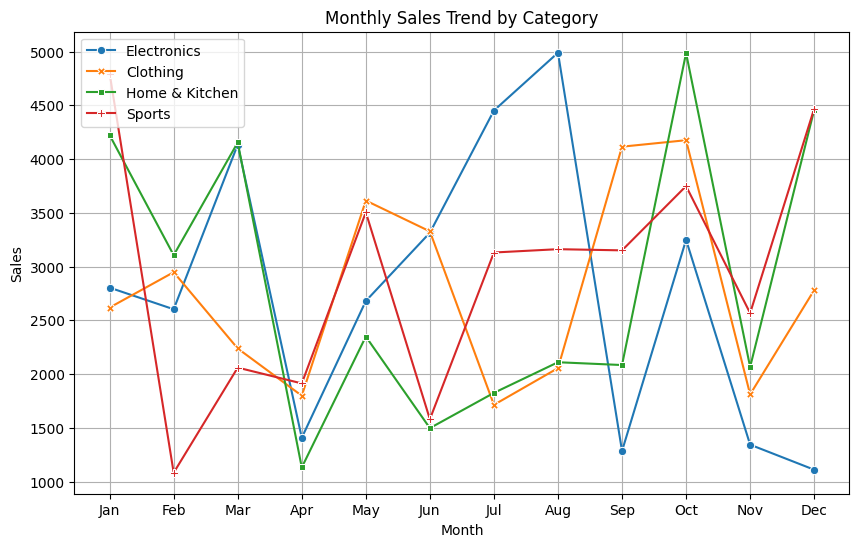

In [10]:
plt.figure(figsize=(10, 6))
sns.lineplot(data=df[categories], markers=True, dashes=False)
plt.title("Monthly Sales Trend by Category")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid(True)
plt.show()

2. Create the following plots:

- Box plots to show the sales distribution for each category.

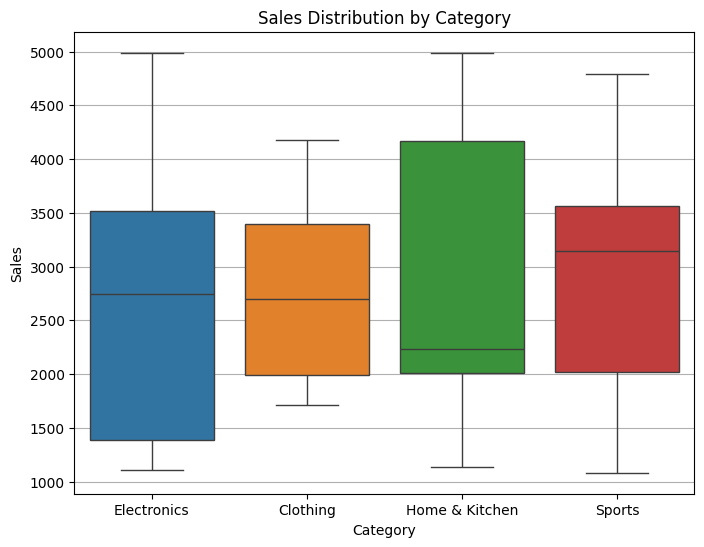

In [11]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df[categories])
plt.title("Sales Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.grid(True, axis="y")
plt.show()

### Q.2 For the array: array = np.array([[1, -2, 3],[-4, 5, -6]])

In [12]:
array = np.array([[1, -2, 3], [-4, 5, -6]])
print(array)

[[ 1 -2  3]
 [-4  5 -6]]


#### i. Find element-wise absolute value

In [13]:
print(np.abs(array))

[[1 2 3]
 [4 5 6]]


#### ii. Find the 25th, 50th, and 75th percentile of flattened array, for each column, for each row.

In [14]:
q = [25, 50, 75]
print("Flattened:", np.percentile(array.flatten(), q))
print("Each column:")
print(np.percentile(array, q, axis=0))
print("Each row:")
print(np.percentile(array, q, axis=1))

Flattened: [-3.5 -0.5  2.5]
Each column:
[[-2.75 -0.25 -3.75]
 [-1.5   1.5  -1.5 ]
 [-0.25  3.25  0.75]]
Each row:
[[-0.5 -5. ]
 [ 1.  -4. ]
 [ 2.   0.5]]


#### iii. Mean, Median and Standard Deviation of flattened array, of each column, and each row

In [15]:
flat = array.flatten()
print("Flattened:", flat.mean(), np.median(flat), flat.std())
print("Each column:", array.mean(axis=0), np.median(array, axis=0), array.std(axis=0))
print("Each row:", array.mean(axis=1), np.median(array, axis=1), array.std(axis=1))

Flattened: -0.5 -0.5 3.8622100754188224
Each column: [-1.5  1.5 -1.5] [-1.5  1.5 -1.5] [2.5 3.5 4.5]
Each row: [ 0.66666667 -1.66666667] [ 1. -4.] [2.05480467 4.78423336]


### Q.3 For the array: a = np.array([-1.8, -1.6, -0.5, 0.5, 1.6, 1.8, 3.0]).

#### i. Find floor, ceiling and truncated value, rounded values

In [16]:
a = np.array([-1.8, -1.6, -0.5, 0.5, 1.6, 1.8, 3.0])
print("Floor    :", np.floor(a))
print("Ceiling  :", np.ceil(a))
print("Truncated:", np.trunc(a))
print("Rounded  :", np.round(a))

Floor    : [-2. -2. -1.  0.  1.  1.  3.]
Ceiling  : [-1. -1. -0.  1.  2.  2.  3.]
Truncated: [-1. -1. -0.  0.  1.  1.  3.]
Rounded  : [-2. -2. -0.  0.  2.  2.  3.]


### Q.4 WAP to swap two elements in a list in Python Using a Temporary Variable.

In [17]:
lst = [10, 20, 30, 40, 50]
print("Before:", lst)
i, j = 1, 3
temp = lst[i]
lst[i] = lst[j]
lst[j] = temp
print("After :", lst)

Before: [10, 20, 30, 40, 50]
After : [10, 40, 30, 20, 50]


### Q.5 Write a Python program to swap two elements in a set by converting it to a list first.

In [18]:
s = {10, 20, 30, 40, 50}
print("Before:", s)
l = list(s)
l[1], l[3] = l[3], l[1]
s = set(l)
print("List after swap:", l)
print("Set after:", s)

Before: {50, 20, 40, 10, 30}
List after swap: [50, 10, 40, 20, 30]
Set after: {40, 10, 50, 20, 30}
